# Scan reach, sensitivities and shape optimization

A lumped-element detector converts an axion signal into flux in a resonant pickup. This notebook turns its coupling and inductance into a sensitivity curve, sizes a magnet for a sensitivity target under a peak-field limit, and then uses shape sensitivities and a bounded search to optimize a physical figure of merit. The solved designs come from the [lumped-element notebook](lumped_element.ipynb).

In [1]:
import math, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import axionfem as af
from axionfem import scan, squid

print("axionFEM", af.__version__)
RUNS = Path(tempfile.mkdtemp(prefix="axf_reach_"))    # solver run directories
plt.rcParams.update({"figure.dpi": 80, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
# one hue per topology
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"
COL = {"toroid": BLUE, "solenoid": ORANGE, "core": GREEN}


def solve(design, tag, **kw):
    """Solve in RUNS/tag and report the number of unknowns and any solver warning."""
    r = design.solve(RUNS / tag, verbose=0, **kw)
    w = [x for x in (r.data.get("warnings") or []) if "background field is present" not in x]
    print(f"  {tag}: {r.data['mesh']['dofs']} DOFs" + (f", warnings: {w}" if w else ""))
    return r

axionFEM 0.1.0


## Scan requirement

The signal coupling $\Psi$ and pickup inductance $L_p$ determine the scan figure of merit. For time allocated to follow the DFSZ axion target,

$$
\mathcal F=\frac{\Psi^4}{L_p^2},\qquad
g_{95}(m_a)=g_{\rm DFSZ}(m_a)\left(\frac{\mathcal F_{\rm req}}{\mathcal F}\right)^{1/4}.
$$

Here $g_{95}$ is the expected 95% upper limit and $\mathcal F_{\rm req}$ is the requirement for the chosen noise, band and live time. The figure of merit uses natural Heaviside–Lorentz units, reported in $\mathrm{T^4m^{10}}$.

`af.requirement` returns the requirement; `scan.BENCHMARKS` supplies resonator quality factor `Q`, temperature `T` in kelvin and amplifier noise `eta_A`. These benchmarks are illustrative presets: replace them with the parameters of your own readout.

In [2]:
print(f"{'benchmark':22s}{'Q':>8s}{'T [mK]':>8s}{'eta_A':>7s}{'F_req [T^4 m^10]':>18s}{'g_DFSZ(m1) [1/GeV]':>20s}")
for name, bm in scan.BENCHMARKS.items():
    rq = af.requirement(name)
    print(f"{name:22s}{bm['Q']:8.0e}{bm['T']*1e3:8.0f}{bm['eta_A']:7.1f}{rq['F_req_natural_T4_m10']:18.6e}"
          f"{rq['g_min_GeV']:20.4e}")
f1, f2 = 120.9e3, 1.0e6
print(f"scan band {f1/1e3} kHz - {f2/1e6} MHz = {scan.freq_to_mass(f1)*1e9:.3f} - {scan.freq_to_mass(f2)*1e9:.3f} neV; "
      f"fraction of the time in the lowest octave: {(1 - 2**-4) / (1 - (f1 / f2)**4):.3f}")

benchmark                    Q  T [mK]  eta_A  F_req [T^4 m^10]  g_DFSZ(m1) [1/GeV]
optimistic               2e+07      10    0.1      1.043768e+04          9.1351e-20
conservative             1e+06      30   10.0      6.262608e+07          9.1351e-20
conservative_solenoid    1e+05      30   10.0      6.262608e+08          9.1351e-20
scan band 120.9 kHz - 1.0 MHz = 0.500 - 4.136 neV; fraction of the time in the lowest octave: 0.938


The table shows how readout noise changes the required figure of merit. The last line gives the scan band and the fraction of observing time spent in its lowest octave.

As a consistency check, the requirement has a closed form in the thermal limit, where $\Theta$ is the signal-model factor of the scan and $Q_a$ the axion quality factor.

In [3]:
EV_PER_K, RHO_EV4 = 8.617333262e-5, 2.305051669e-6          # k_B [eV/K], 0.3 GeV/cm^3 [eV^4]
EV_INV_PER_S, YEAR_S, T4M10_EV2 = 1.519267447e15, 3.15576e7, 1.627097598e76

def F_req_closed(bm, f1=120.9e3, f2=1.0e6, t_yr=3.0, Q_a=6.8e5, Theta=2.71):
    """Thermal-limit scan requirement in natural units, returned in T^4 m^10."""
    m1, m2 = scan.freq_to_mass(f1), scan.freq_to_mass(f2)
    g1 = float(scan.g_qcd([m1])[0]) * 1e-9                         # GeV^-1 -> eV^-1
    F = (3 * math.sqrt(3) / math.pi ** 2 * Theta * bm["eta_A"] * bm["T"] * EV_PER_K
         / (Q_a * bm["Q"] * RHO_EV4 ** 2 * g1 ** 4 * t_yr * YEAR_S * EV_INV_PER_S) * (1 - (m1 / m2) ** 4))
    return F / T4M10_EV2

print(f"{'benchmark':22s}{'Q':>9s}{'T [mK]':>8s}{'eta_A':>7s}{'F_req [T^4 m^10]':>18s}{'closed form':>13s}{'g_DFSZ(m1)':>12s}")
for name, bm in scan.BENCHMARKS.items():
    rq = af.requirement(name)
    print(f"{name:22s}{bm['Q']:9.0e}{bm['T']*1e3:8.0f}{bm['eta_A']:7.1f}{rq['F_req_natural_T4_m10']:18.6e}"
          f"{F_req_closed(bm):13.6e}{rq['g_min_GeV']:12.4e}")

benchmark                     Q  T [mK]  eta_A  F_req [T^4 m^10]  closed form  g_DFSZ(m1)
optimistic                2e+07      10    0.1      1.043768e+04 1.043768e+04  9.1351e-20
conservative              1e+06      30   10.0      6.262608e+07 6.262608e+07  9.1351e-20
conservative_solenoid     1e+05      30   10.0      6.262608e+08 6.262608e+08  9.1351e-20


## Required field

Solve a toroid and inspect its `benchmarks` entries. `amplitude_scale` multiplies the magnet field to reach the requirement; the following values report the resulting energy and peak field.

In [4]:
tor = af.template("toroid", R=1.0, H=2.0)
res = solve(tor, "toroid")
print(f"F = {res.coupling['F_natural_T4_m10']:.4e} T^4 m^10, W = {res.W:.4e} J, B_max = {res.B_max:.4f} T\n")
for b in res.data["benchmarks"]:
    s = b["amplitude_scale"]
    print(f"{b['name']}:  F_req = {b['F_req_natural_T4_m10']:.4e},  F/F_req = {b['F_over_F_req']:.4e}")
    print(f"    amplitude scale  {s:.4f}   (F_req/F)^(1/4) = {b['F_over_F_req'] ** -0.25:.4f}")
    print(f"    W at req         {b['W_mag_at_req_J']:.4e} J   s^2 W = {s**2 * res.W:.4e} J")
    print(f"    B_max at req     {b['B_max_at_req_T']:.3f} T     s B_max = {s * res.B_max:.3f} T")

  toroid: 79774 DOFs
F = 2.6140e-04 T^4 m^10, W = 1.0210e+05 J, B_max = 0.3297 T

optimistic:  F_req = 1.0438e+04,  F/F_req = 2.5044e-08
    amplitude scale  79.4920   (F_req/F)^(1/4) = 79.4920
    W at req         6.4517e+08 J   s^2 W = 6.4517e+08 J
    B_max at req     26.212 T     s B_max = 26.212 T
conservative:  F_req = 6.2626e+07,  F/F_req = 4.1740e-12
    amplitude scale  699.6183   (F_req/F)^(1/4) = 699.6183
    W at req         4.9975e+10 J   s^2 W = 4.9975e+10 J
    B_max at req     230.695 T     s B_max = 230.695 T


## Reach

`res.reach` defaults to `amplitude="required"`, which rescales the magnet to the target sensitivity. `amplitude="as_designed"` keeps the solved current. `allocation="log_uniform"` instead gives equal time to each logarithmic frequency interval.

The returned `band` records the assumptions; `g95_GeV` contains the coupling limits.

In [5]:
r_req = res.reach("optimistic")                                   # field scaled to F = F_req
r_as = res.reach("optimistic", amplitude="as_designed")           # 1e6 A-turns
r_con = res.reach("conservative")                                 # scaled to the conservative requirement
s_opt = res.benchmark("optimistic")["amplitude_scale"]
r_log = scan.reach(res.Psi * s_opt, res.L_p, "optimistic", allocation="log_uniform")
print("band:", {k: r_req["band"][k] for k in ("f_min_Hz", "f_max_Hz", "live_time_yr", "allocation", "benchmark", "model")
                if k in r_req["band"]})
for lab, r in (("optimistic, at requirement", r_req), ("optimistic, as designed", r_as),
               ("conservative, at its requirement", r_con), ("optimistic, log-uniform", r_log)):
    ratio = np.asarray(r["g95_GeV"]) / np.asarray(r["g_target_GeV"])
    print(f"{lab:34s} g95/g_DFSZ = {ratio.min():.4g} .. {ratio.max():.4g};  time to DFSZ at m1: {3 * ratio[0]**4:.3g} yr")
print(f"(F_req/F)^(1/4) as designed = {res.benchmark('optimistic')['F_over_F_req'] ** -0.25:.4f};  "
      f"log-uniform/target at m1 = {(np.asarray(r_log['g95_GeV']) / np.asarray(r_req['g95_GeV']))[0]:.4f} "
      f"(formula for this band: {(4 * math.log(f2 / f1) / (1 - (f1 / f2) ** 4)) ** 0.25:.4f})")

band: {'f_min_Hz': 120900.0, 'f_max_Hz': 999999.9999999999, 'live_time_yr': 3.0, 'allocation': 'target', 'benchmark': 'optimistic', 'model': 'DFSZ'}
optimistic, at requirement         g95/g_DFSZ = 1 .. 1;  time to DFSZ at m1: 3 yr
optimistic, as designed            g95/g_DFSZ = 79.49 .. 79.49;  time to DFSZ at m1: 1.2e+08 yr
conservative, at its requirement   g95/g_DFSZ = 1 .. 1;  time to DFSZ at m1: 3 yr
optimistic, log-uniform            g95/g_DFSZ = 0.2061 .. 1.705;  time to DFSZ at m1: 25.4 yr
(F_req/F)^(1/4) as designed = 79.4920;  log-uniform/target at m1 = 1.7051 (formula for this band: 1.7051)


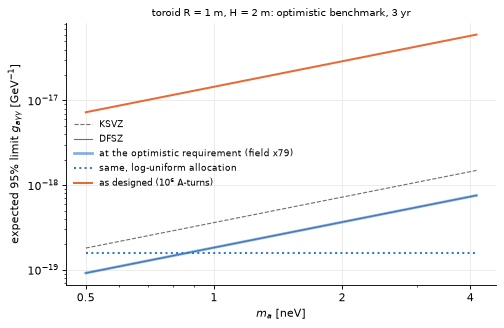

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
m = np.asarray(r_req["m_eV"]) * 1e9
ax.plot(m, scan.g_qcd(r_req["m_eV"], "KSVZ"), color=GREY, lw=1, ls="--", label="KSVZ")
ax.plot(m, r_req["g_target_GeV"], color=GREY, lw=1, label="DFSZ")
ax.plot(m, r_req["g95_GeV"], color=BLUE, lw=2.4, alpha=0.6, label=f"at the optimistic requirement (field x{s_opt:.0f})")
ax.plot(np.asarray(r_log["m_eV"]) * 1e9, r_log["g95_GeV"], color=BLUE, ls=":", label="same, log-uniform allocation")
ax.plot(np.asarray(r_as["m_eV"]) * 1e9, r_as["g95_GeV"], color=ORANGE, label="as designed ($10^6$ A-turns)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("$m_a$ [neV]"); ax.set_ylabel(r"expected 95% limit $g_{a\gamma\gamma}$ [GeV$^{-1}$]")
ax.set_xticks([0.5, 1, 2, 4]); ax.set_xticklabels(["0.5", "1", "2", "4"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("toroid R = 1 m, H = 2 m: optimistic benchmark, 3 yr", fontsize=9); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

The required-field curve follows DFSZ by construction. Lower curves mean sensitivity to weaker couplings; the log-uniform curve shows the effect of redistributing observing time.

## Size at fixed shape

Scale every length of the design by $\ell$ and set the current so that the detector stays at the requirement. For a linear, iron-free magnetoquasistatic design the stored energy at the requirement then scales as $\ell^{-2}$ and the peak field as $\ell^{-5/2}$: a larger magnet of the same shape reaches the same sensitivity with less energy and a lower field. The next cell checks both laws against separately solved toroids.

  toroid_R0.5: 79774 DOFs
  toroid_R0.8: 79802 DOFs
  toroid_R1.25: 79674 DOFs
  toroid_R2: 79774 DOFs
  toroid_R3.2: 79802 DOFs
  toroid_R5: 79674 DOFs
 R [m]  W@req [MJ]     W law  B_max@req [T]    B law
  0.50        2581      2581          148.3    148.3
  0.80        1008      1008          45.79    45.79
  1.25       412.9     412.9             15       15
  2.00       161.3     161.3          4.634    4.634
  3.20          63        63          1.431    1.431
  5.00       25.81     25.81         0.4689   0.4689


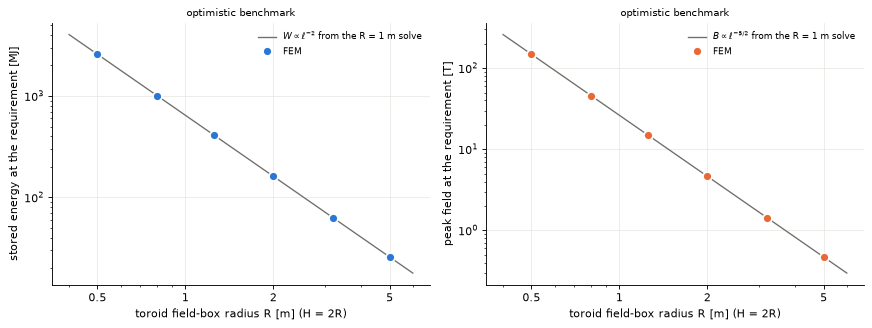

In [7]:
sizes = np.array([0.5, 0.8, 1.25, 2.0, 3.2, 5.0])
b = res.benchmark("optimistic")
rows = []
for Rs in sizes:
    bb = solve(af.template("toroid", R=float(Rs), H=2.0 * Rs), f"toroid_R{Rs:g}").benchmark("optimistic")
    rows.append((Rs, bb["W_mag_at_req_J"], bb["B_max_at_req_T"]))
rows = np.array(rows)
l = np.geomspace(0.4, 6, 200)                         # field-box radius [m]; the laws from the R = 1 m solve alone

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2))
ax0.plot(l, b["W_mag_at_req_J"] * l ** -2.0 / 1e6, color=GREY, lw=1.2, label="$W \\propto \\ell^{-2}$ from the R = 1 m solve")
ax0.plot(rows[:, 0], rows[:, 1] / 1e6, "o", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM")
ax0.set_ylabel("stored energy at the requirement [MJ]")
ax1.plot(l, b["B_max_at_req_T"] * l ** -2.5, color=GREY, lw=1.2, label="$B \\propto \\ell^{-5/2}$ from the R = 1 m solve")
ax1.plot(rows[:, 0], rows[:, 2], "o", ms=8, color=ORANGE, mec="white", mew=1.5, label="FEM")
ax1.set_ylabel("peak field at the requirement [T]")
for ax in (ax0, ax1):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("toroid field-box radius R [m] (H = 2R)")
    ax.set_xticks([0.5, 1, 2, 5]); ax.set_xticklabels(["0.5", "1", "2", "5"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title("optimistic benchmark", fontsize=9); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"{'R [m]':>6s}{'W@req [MJ]':>12s}{'W law':>10s}{'B_max@req [T]':>15s}{'B law':>9s}")
for Rs, W, B in rows:
    print(f"{Rs:6.2f}{W / 1e6:12.4g}{b['W_mag_at_req_J'] * Rs ** -2 / 1e6:10.4g}{B:15.4g}{b['B_max_at_req_T'] * Rs ** -2.5:9.4g}")

### Choose a size: a peak-field limit

The conductor limits the peak field. With $B_{\max}\propto\ell^{-5/2}$, the smallest toroid of this shape that reaches the requirement with a peak field of at most $B_{\rm cap}$ has $\ell=(B_{\rm req}/B_{\rm cap})^{2/5}$, where $B_{\rm req}$ is the peak field the $R$ = 1 m design needs. Rebuild at that size, with the current scaled as $s\,\ell^{-3/2}$, and check the requirement and the field. $B_{\rm cap}$ = 5 T is an illustrative value.

In [8]:
B_cap = 5.0                                           # illustrative peak-field limit [T]
ell = (b["B_max_at_req_T"] / B_cap) ** 0.4
p0 = tor.resolved_params()
print(f"length scale l = {ell:.5f}: R = {p0['R'] * ell:.3f} m, H = {p0['H'] * ell:.3f} m; "
      f"predicted W = {b['W_mag_at_req_J'] * ell ** -2 / 1e6:.2f} MJ")

opt = af.template("toroid", R=p0["R"] * ell, H=p0["H"] * ell)
opt.set(NI=p0["NI"] * b["amplitude_scale"] * ell ** -1.5)
res_o = solve(opt, "toroid_field_limited")
bo = res_o.benchmark("optimistic")
print(f"re-solved at R = {opt.resolved_params()['R']:.3f} m, NI = {opt.resolved_params()['NI']:.4e}: "
      f"F/F_req = {bo['F_over_F_req']:.6f}, B_max = {res_o.B_max:.3f} T, W = {res_o.W / 1e6:.2f} MJ")

length scale l = 1.94005: R = 1.940 m, H = 3.880 m; predicted W = 171.42 MJ
  toroid_field_limited: 79878 DOFs
re-solved at R = 1.940 m, NI = 2.9417e+07: F/F_req = 1.000000, B_max = 5.000 T, W = 171.42 MJ


These scalings assume linear, iron-free designs without fixed fluxes, circuits or background fields, below pickup self-resonance, and no binding conductor limit other than the peak field.

## Reach with readout chains

`scan.reach` takes SI inputs and returns limits; `squid.benchmark` supplies the noise of a SQUID chain (`axionfem.squid` is beta; see the [readout notebook](readout_squid.ipynb)). The local scan assumes weak signals, dense tuning, narrow sensitivity bands, and dwell times longer than coherence and ring-up times. A coupling ratio $g_{95}/g_{\rm DFSZ}$ below one reaches the DFSZ target.

We compute the reach of the field-limited toroid for the benchmark presets and two SQUID chains.

case                                   g95/g_DFSZ  eta_A(120.9 kHz)  time to DFSZ
optimistic (eta_A = 0.1)                    1.000              0.10          3 yr
conservative (eta_A = 10)                   8.801             10.00    1.8e+04 yr
Q = 1e6, 30 mK, C1+low+RT chain             8.736              9.71  1.747e+04 yr
Q = 2e7, 10 mK, C1 alone                    2.467              3.70      111.1 yr


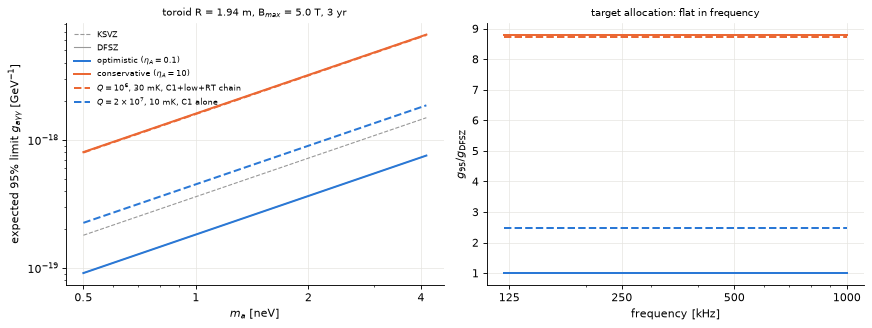

In [9]:
cases = [("optimistic ($\\eta_A=0.1$)", "optimistic (eta_A = 0.1)", "optimistic", BLUE, "-"),
         ("conservative ($\\eta_A=10$)", "conservative (eta_A = 10)", "conservative", ORANGE, "-"),
         ("$Q=10^6$, 30 mK, C1+low+RT chain", "Q = 1e6, 30 mK, C1+low+RT chain",
          squid.benchmark("C1+low+RT", Q=1e6, T_K=0.03), ORANGE, "--"),
         ("$Q=2\\times10^7$, 10 mK, C1 alone", "Q = 2e7, 10 mK, C1 alone",
          squid.benchmark("C1", Q=2e7, T_K=0.01), BLUE, "--")]
reach = {lab: scan.reach(res_o.Psi, res_o.L_p, bm, n=60) for lab, _, bm, _, _ in cases}

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2))
ref = next(iter(reach.values()))
m_neV = ref["m_eV"] * 1e9
ax0.plot(m_neV, scan.g_qcd(ref["m_eV"], "KSVZ"), color="0.6", lw=1, ls="--", label="KSVZ")
ax0.plot(m_neV, ref["g_target_GeV"], color="0.6", lw=1, label="DFSZ")
print(f"{'case':38s}{'g95/g_DFSZ':>11s}{'eta_A(120.9 kHz)':>18s}{'time to DFSZ':>14s}")
for lab, txt, bm, col, ls in cases:
    r = reach[lab]
    ratio = r["g95_GeV"] / r["g_target_GeV"]
    ax0.plot(r["m_eV"] * 1e9, r["g95_GeV"], color=col, ls=ls, label=lab)
    ax1.plot(r["f_Hz"] / 1e3, ratio, color=col, ls=ls, label=lab)
    eta0 = np.atleast_1d(r["band"]["eta_A"])[0]
    print(f"{txt:38s}{np.median(ratio):11.3f}{eta0:18.2f}{3 * np.median(ratio) ** 4:11.4g} yr")
ax0.set_xscale("log"); ax0.set_yscale("log"); ax0.set_xlabel("$m_a$ [neV]")
ax0.set_xticks([0.5, 1, 2, 4]); ax0.set_xticklabels(["0.5", "1", "2", "4"]); ax0.xaxis.set_minor_formatter(plt.NullFormatter())
ax0.set_ylabel(r"expected 95% limit $g_{a\gamma\gamma}$ [GeV$^{-1}$]")
ax0.set_title(f"toroid R = {opt.resolved_params()['R']:.2f} m, B$_{{max}}$ = {res_o.B_max:.1f} T, 3 yr", fontsize=9)
ax0.legend(fontsize=7.5)
ax1.set_xscale("log"); ax1.set_xlabel("frequency [kHz]")
ax1.set_xticks([125, 250, 500, 1000]); ax1.set_xticklabels(["125", "250", "500", "1000"]); ax1.xaxis.set_minor_formatter(plt.NullFormatter()); ax1.set_ylabel(r"$g_{95}/g_{\rm DFSZ}$")
ax1.set_title("target allocation: flat in frequency", fontsize=9)
fig.tight_layout(); plt.show()

## Scan band

These resizing laws assume linear MQS models without iron or active field caps. We vary the scan band to check how the requirement, the field-limited size and its stored energy scale: $\mathcal F_{\rm req}\propto m_1^{-4}$, and at a fixed peak field $\ell\propto\mathcal F_{\rm req}^{1/10}$ and $W\propto\mathcal F_{\rm req}^{3/10}$.

In [10]:
f1s = np.array([30e3, 60e3, 120.9e3, 240e3, 480e3])
ss = []
for f1 in f1s:
    d = tor.copy()
    d.doc["scan"] = {"f_min": float(f1), "f_max": float(f1 * 991.4 / 120.9)}
    bb = solve(d, f"toroid_fmin{f1/1e3:g}k").benchmark("optimistic")
    l_ = (bb["B_max_at_req_T"] / B_cap) ** 0.4
    ss.append((bb["F_req_natural_T4_m10"], l_, bb["W_mag_at_req_J"] * l_ ** -2))
ss = np.array(ss)
m1 = np.array([scan.freq_to_mass(f) for f in f1s])
slope = lambda x, y: np.polyfit(np.log(x), np.log(y), 1)[0]
print(f"{'f_min [kHz]':>12s}{'m1 [neV]':>10s}{'F_req':>12s}{'l':>8s}{'W [MJ]':>10s}")
for f1, m, (F, l_, W) in zip(f1s, m1, ss):
    print(f"{f1/1e3:12.1f}{m*1e9:10.3f}{F:12.4e}{l_:8.3f}{W / 1e6:10.2f}")
print(f"\nd ln F_req / d ln m1 = {slope(m1, ss[:, 0]):+.5f}   (expected -4)")
print(f"d ln l     / d ln F_req = {slope(ss[:, 0], ss[:, 1]):+.5f}   (expected 1/10)")
print(f"d ln W     / d ln F_req = {slope(ss[:, 0], ss[:, 2]):+.5f}   (expected 3/10)")

# with f_max held at 1 MHz instead, the bracket [1 - (m1/m2)^4] breaks the pure power law slightly
Fq = np.array([af.requirement("optimistic", f_min=float(f), f_max=1e6)["F_req_natural_T4_m10"] for f in f1s])
print(f"\nf_max fixed at 1 MHz: d ln F_req / d ln m1 = {slope(m1, Fq):+.4f}")

  toroid_fmin30k: 79774 DOFs
  toroid_fmin60k: 79774 DOFs
  toroid_fmin120.9k: 79774 DOFs
  toroid_fmin240k: 79774 DOFs
  toroid_fmin480k: 79774 DOFs
 f_min [kHz]  m1 [neV]       F_req       l    W [MJ]
        30.0     0.124  2.7531e+06   3.388    912.88
        60.0     0.248  1.7207e+05   2.568    397.36
       120.9     0.500  1.0438e+04   1.940    171.42
       240.0     0.993  6.7214e+02   1.475     75.28
       480.0     1.985  4.2009e+01   1.118     32.77

d ln F_req / d ln m1 = -4.00000   (expected -4)
d ln l     / d ln F_req = +0.10000   (expected 1/10)
d ln W     / d ln F_req = +0.30000   (expected 3/10)

f_max fixed at 1 MHz: d ln F_req / d ln m1 = -4.0162


## Shape sensitivities

A shape sensitivity measures the change in one of the solved quantities per change in a design parameter. axionFEM computes them with a discrete adjoint on the current mesh; the adjoint supports axisymmetric magnetoquasistatic designs with linear materials (3D, full-wave results and RF loss budgets are not differentiated). For a solenoid, `x` is the coax inner radius divided by the winding inner radius. We compute the derivatives of the scan figure of merit $\mathcal F$ with respect to `x`; `gradient` is in SI units and `relative` is the fractional change of the objective per fractional change of `x`.

In [11]:
sol = af.template("solenoid")
res_s = solve(sol, "solenoid")
s = res_s.sensitivities(params=["x"], objectives=["F"])
print(f"x = {sol.resolved_params()['x']}:  dF/dx = {s['gradient']['F']['x']:.4e},  relative dlnF/dlnx = {s['relative']['F']['x']:+.4f}")

# check against a central finite difference of full solves
h = 0.01
Fp = solve(sol.with_params(x=sol.resolved_params()["x"] * (1 + h)), "sol_xp").coupling["F_SI_T4_H2_m8"]
Fm = solve(sol.with_params(x=sol.resolved_params()["x"] * (1 - h)), "sol_xm").coupling["F_SI_T4_H2_m8"]
fd = (math.log(Fp) - math.log(Fm)) / (math.log(1 + h) - math.log(1 - h))
print(f"finite difference of ln F against ln x: {fd:+.4f}")

  solenoid: 73566 DOFs
x = 0.534:  dF/dx = 2.4782e-15,  relative dlnF/dlnx = +0.0765
  sol_xp: 73382 DOFs
  sol_xm: 73602 DOFs
finite difference of ln F against ln x: +0.0764


These are derivatives on the current mesh: establish mesh convergence before optimizing. `af.optimize` combines such gradients with a bounded search. The next cell searches for a local minimum, over `x`, of the solenoid's stored energy at the scan requirement (`W_at_req`, optimistic benchmark): the field energy a magnet of this shape needs to reach the target sensitivity. `converged` and `message` describe the search termination; `history` records the iterations and `design` holds the optimized design document. Field limits are only reported unless they are added as explicit `constraints` on `sc_surface_at_req` or `B_peak_at_req`.

In [12]:
out = af.optimize(sol, objective="W_at_req:optimistic", params={"x": (0.3, 0.8)}, max_iter=30, verbose=0,
                  workdir=RUNS / "optimize")
print(out["converged"], "|", out["message"])
print("optimum:", {k: round(v, 5) for k, v in out["parameters"].items()}, "| W at the requirement [MJ]:",
      round(out["value"] / 1e6, 4), "| iterations:", len(out["history"]))
x0 = sol.resolved_params()["x"]
print(f"starting point x = {x0}: W at the requirement {res_s.benchmark('optimistic')['W_mag_at_req_J'] / 1e6:.4f} MJ")

True | CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
optimum: {'x': 0.54452} | W at the requirement [MJ]: 665.1511 | iterations: 4
starting point x = 0.534: W at the requirement 665.4026 MJ


A global search with differential evolution is available as `af.global_optimize`; it accepts the same objectives and constraints and a budget of generations. See the [optimization guide](../docs/guides/optimization.md) and the [scan notes](../docs/physics/scan_and_signal.md).